# Approximating Vermeer's Girl with a Pearl Earring using a Genetic Algorithm

In `project_v0`, we built a first working Genetic Algorithm for this problem. This version continues from that baseline, but with a stronger focus on understanding the search process and connecting the implementation to the concepts studied in class.

The main story of this notebook is:

1. Start from a simple baseline GA.
2. Observe how the search evolves over time.
3. Study how selection, crossover, and mutation affect the result.
4. Measure population diversity to detect premature convergence.
5. Try diversity-preserving mechanisms such as fitness sharing or restricted mating.

The goal of the project is to create and run a Genetic Algorithm to approximate Vermeer's "Girl with a Pearl Earring" using only 100 triangles.

Each individual represents one candidate image. Its fitness is measured using the RMSE between the generated image and the target image, comparing the images pixel by pixel. Lower fitness values mean a better approximation.

## Notebook roadmap

The notebook is organized as an experimental story rather than only a sequence of code blocks:

1. Define the representation of a solution and the fitness function.
2. Build a reusable GA loop with configurable operators.
3. Run a baseline experiment and plot the evolution of the search.
4. Compare different crossover and mutation operators.
5. Search for good combinations of operators and parameters.
6. Measure population diversity and use it to explain stagnation or premature convergence.
7. Try mechanisms to preserve diversity, such as fitness sharing or restricted mating.

This structure lets us explain each new implementation choice as a response to something observed in the previous experiment.

## 0. Imports and constants

In [1]:
import numpy as np
from PIL import Image

from src.solution import Solution
from src.ga_loop import base_ga_loop, mutation_weight_decay_ga_loop
from src.selection import tournament_selection
from src.crossover import uniform_crossover, one_point_row_crossover, two_point_row_crossover, geometry_color_separated_uniform_crossover, arithmetic_blend_crossover
from src.mutation import random_per_gene_reset_mutation, gaussian_creep_mutation, whole_triangle_mutation, layer_order_mutation
from src.utils import plot_fitess_evolution

In [2]:
IMAGE_PATH = "girl_pearl_earing.png"
IMAGE_WIDTH = 300
IMAGE_HEIGHT = 400
N_TRIANGLES = 100
TARGET_IMAGE_ALPHA = np.asarray(Image.open(IMAGE_PATH).convert("RGBA"), dtype=np.uint8)
TARGET_IMAGE_NO_ALPHA = np.asarray(Image.open(IMAGE_PATH).convert("RGB"), dtype=np.uint8)

## 1. Defining the solution representation and fitness

For the solution representation we settled on having an array that represents the 100 triangles, each of the triangles being represented also by an array with the following structure: [x1, y1, x2, y2, x3, y3, r, g, b, a]

x1 to y3 represent the coordinates of each of the points of the triangle

r (red), g (green), b (blue) and a (alpha) represent the color channels of the triangle

We can solve this problem with and without transparency, and the solutions will look different, so maybe it is worth trying both of the ways, using an adaptable solution class?

We have defined the `Solution` class in `src/solution.py`, and here is an example of it, using transparency:

In [3]:
example_solution = Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True)

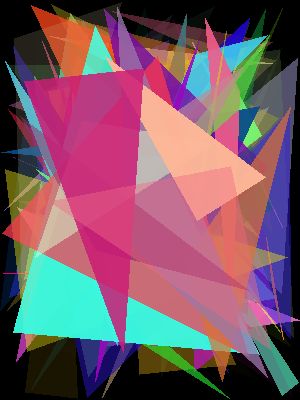

In [5]:
example_solution.render()

In [6]:
example_solution.calculate_fitness()

np.float16(77.06)

And now an example without transparency:

In [6]:
example_solution = Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_NO_ALPHA, use_transparency=False)

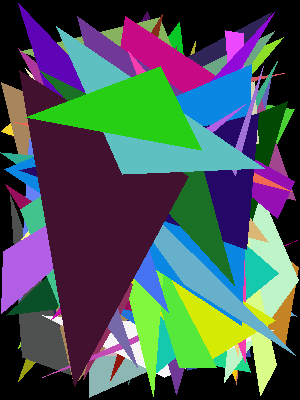

In [7]:
example_solution.render()

In [8]:
example_solution.calculate_fitness()

np.float16(96.06)

here we will create the genetic algorithm loop

check if it makes sense to define this as a class or it should be a function

## 2. Baseline GA run

here we will define a baseline run, using tournament selection because the teacher recommended to try it first, uniform crossover and random per gene mutation as these were the simplest ones

we will always use a random seed to have comparable runs with different hyperparameters and selection, crossover and mutation functions

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = random_per_gene_reset_mutation,
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 66.12, Best: 60.84; Mutation rate: 0.010; 0.89s/iteration
Iteration 10 - Fitness: Avg: 57.91, Best: 52.91; Mutation rate: 0.010; 0.79s/iteration
Iteration 20 - Fitness: Avg: 54.22, Best: 50.88; Mutation rate: 0.010; 0.77s/iteration
Iteration 30 - Fitness: Avg: 51.81, Best: 48.94; Mutation rate: 0.010; 1.06s/iteration
Iteration 40 - Fitness: Avg: 51.03, Best: 47.72; Mutation rate: 0.010; 0.76s/iteration
Iteration 50 - Fitness: Avg: 50.06, Best: 47.00; Mutation rate: 0.010; 1.01s/iteration
Iteration 60 - Fitness: Avg: 49.00, Best: 46.31; Mutation rate: 0.010; 0.73s/iteration
Iteration 70 - Fitness: Avg: 47.56, Best: 45.22; Mutation rate: 0.010; 0.75s/iteration
Iteration 80 - Fitness: Avg: 46.78, Best: 43.84; Mutation rate: 0.010; 0.76s/iteration
Iteration 90 - Fitness: Avg: 46.25, Best: 43.53; Mutation rate: 0.010; 0.76s/iteration
Iteration 100 - Fitness: Avg: 46.19, Best: 43.41; Mutation rate: 0.010; 0.72s/iteration


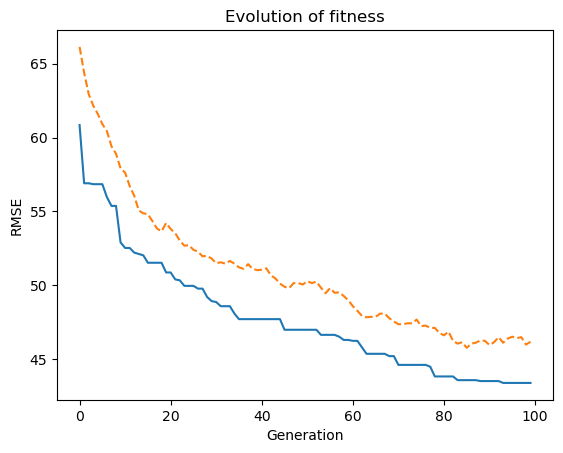

In [11]:
plot_fitess_evolution(history)

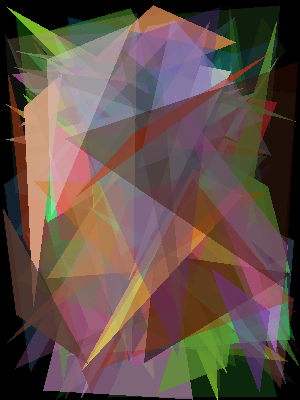

In [12]:
best_solution.render()

running without transparency

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_NO_ALPHA, use_transparency=False),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = random_per_gene_reset_mutation,
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 92.00, Best: 82.94; Mutation rate: 0.010; 0.59s/iteration
Iteration 10 - Fitness: Avg: 80.94, Best: 76.06; Mutation rate: 0.010; 0.53s/iteration
Iteration 20 - Fitness: Avg: 77.31, Best: 73.56; Mutation rate: 0.010; 0.52s/iteration
Iteration 30 - Fitness: Avg: 74.38, Best: 70.19; Mutation rate: 0.010; 0.54s/iteration
Iteration 40 - Fitness: Avg: 72.12, Best: 68.50; Mutation rate: 0.010; 0.63s/iteration
Iteration 50 - Fitness: Avg: 69.19, Best: 65.06; Mutation rate: 0.010; 0.51s/iteration
Iteration 60 - Fitness: Avg: 67.69, Best: 63.88; Mutation rate: 0.010; 0.61s/iteration
Iteration 70 - Fitness: Avg: 66.38, Best: 63.09; Mutation rate: 0.010; 0.49s/iteration
Iteration 80 - Fitness: Avg: 65.25, Best: 60.03; Mutation rate: 0.010; 0.57s/iteration
Iteration 90 - Fitness: Avg: 64.00, Best: 59.50; Mutation rate: 0.010; 0.49s/iteration
Iteration 100 - Fitness: Avg: 63.22, Best: 59.44; Mutation rate: 0.010; 0.50s/iteration


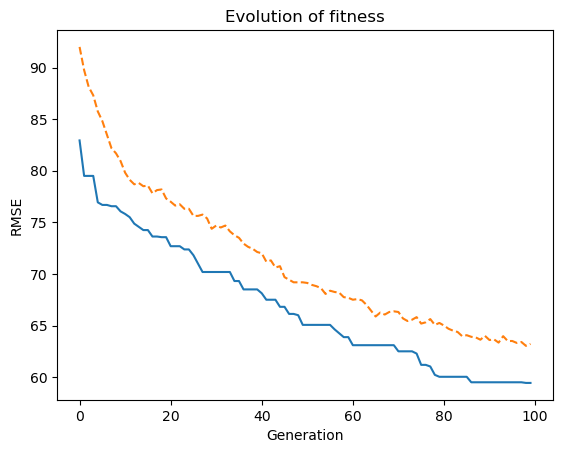

In [14]:
plot_fitess_evolution(history)

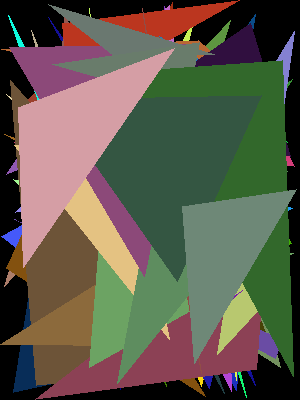

In [15]:
best_solution.render()

for now we will use solutions with transparency, then at the end we will try to get good solutions for both

## 3. Exploring Selection operators

try different selection options

### 3.1. Tournament selection

we started with this one because it was the one recommened by the teacher, as it sometimes allows us to do less fitness calculations so it may be faster

### 3.2. Roulette-wheel selection

### 3.3. Rank-based selection

## 4. Exploring Crossover operators

in this we want to have an overview of the different crossover operators we will try and why they can be good for our problem

### 4.1. Uniform crossover

this was the first one we created

### 4.2. One-point row crossover

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = one_point_row_crossover,
    crossover_rate = 0.9,
    mutation_function = random_per_gene_reset_mutation,
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 66.00, Best: 60.94; Mutation rate: 0.010; 0.88s/iteration
Iteration 10 - Fitness: Avg: 56.00, Best: 51.25; Mutation rate: 0.010; 0.86s/iteration
Iteration 20 - Fitness: Avg: 52.47, Best: 49.84; Mutation rate: 0.010; 0.88s/iteration
Iteration 30 - Fitness: Avg: 51.62, Best: 49.34; Mutation rate: 0.010; 0.71s/iteration
Iteration 40 - Fitness: Avg: 49.81, Best: 46.38; Mutation rate: 0.010; 0.74s/iteration
Iteration 50 - Fitness: Avg: 48.00, Best: 45.59; Mutation rate: 0.010; 0.70s/iteration
Iteration 60 - Fitness: Avg: 47.50, Best: 44.72; Mutation rate: 0.010; 0.70s/iteration
Iteration 70 - Fitness: Avg: 47.53, Best: 44.00; Mutation rate: 0.010; 0.71s/iteration
Iteration 80 - Fitness: Avg: 45.97, Best: 43.06; Mutation rate: 0.010; 0.79s/iteration
Iteration 90 - Fitness: Avg: 45.78, Best: 43.06; Mutation rate: 0.010; 0.80s/iteration
Iteration 100 - Fitness: Avg: 45.28, Best: 41.72; Mutation rate: 0.010; 0.73s/iteration


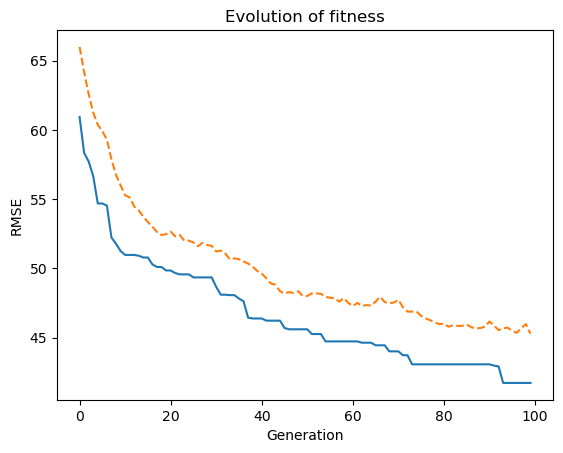

In [4]:
plot_fitess_evolution(history)

### 4.3. Two-point row crossover

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = two_point_row_crossover,
    crossover_rate = 0.9,
    mutation_function = random_per_gene_reset_mutation,
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 66.50, Best: 60.72; Mutation rate: 0.010; 0.80s/iteration
Iteration 10 - Fitness: Avg: 57.28, Best: 53.56; Mutation rate: 0.010; 0.80s/iteration
Iteration 20 - Fitness: Avg: 53.03, Best: 50.66; Mutation rate: 0.010; 0.72s/iteration
Iteration 30 - Fitness: Avg: 51.53, Best: 48.97; Mutation rate: 0.010; 0.71s/iteration
Iteration 40 - Fitness: Avg: 49.38, Best: 46.81; Mutation rate: 0.010; 0.72s/iteration
Iteration 50 - Fitness: Avg: 47.59, Best: 44.97; Mutation rate: 0.010; 0.72s/iteration
Iteration 60 - Fitness: Avg: 46.38, Best: 42.94; Mutation rate: 0.010; 0.78s/iteration
Iteration 70 - Fitness: Avg: 45.97, Best: 42.94; Mutation rate: 0.010; 0.80s/iteration
Iteration 80 - Fitness: Avg: 46.28, Best: 42.94; Mutation rate: 0.010; 0.71s/iteration
Iteration 90 - Fitness: Avg: 46.25, Best: 42.94; Mutation rate: 0.010; 0.72s/iteration
Iteration 100 - Fitness: Avg: 45.81, Best: 42.72; Mutation rate: 0.010; 0.73s/iteration


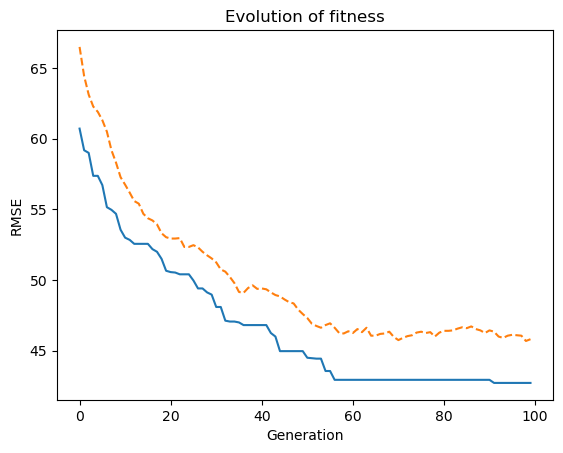

In [4]:
plot_fitess_evolution(history)

### 4.4. Geometry/color separated uniform crossover

For each selected triangle, take coordinates from one parent and color/alpha from the other. 
This is useful because good shapes and good colors may evolve separately.
It is basically uniform crossover, but we don't swap the whole triangle.

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = geometry_color_separated_uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = random_per_gene_reset_mutation,
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 66.31, Best: 59.31; Mutation rate: 0.010; 0.83s/iteration
Iteration 10 - Fitness: Avg: 58.34, Best: 54.88; Mutation rate: 0.010; 0.77s/iteration
Iteration 20 - Fitness: Avg: 56.16, Best: 52.41; Mutation rate: 0.010; 0.77s/iteration
Iteration 30 - Fitness: Avg: 54.53, Best: 51.41; Mutation rate: 0.010; 0.69s/iteration
Iteration 40 - Fitness: Avg: 54.47, Best: 50.12; Mutation rate: 0.010; 0.71s/iteration
Iteration 50 - Fitness: Avg: 51.22, Best: 47.78; Mutation rate: 0.010; 0.76s/iteration
Iteration 60 - Fitness: Avg: 50.19, Best: 46.75; Mutation rate: 0.010; 0.74s/iteration
Iteration 70 - Fitness: Avg: 49.41, Best: 46.75; Mutation rate: 0.010; 0.73s/iteration
Iteration 80 - Fitness: Avg: 49.25, Best: 46.22; Mutation rate: 0.010; 0.70s/iteration
Iteration 90 - Fitness: Avg: 50.28, Best: 46.22; Mutation rate: 0.010; 0.73s/iteration
Iteration 100 - Fitness: Avg: 49.78, Best: 46.22; Mutation rate: 0.010; 0.73s/iteration


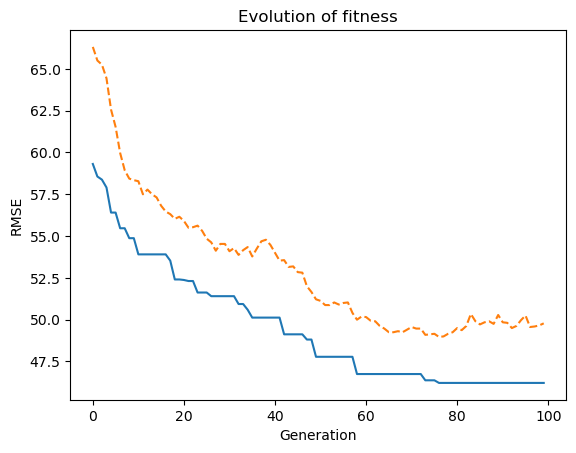

In [4]:
plot_fitess_evolution(history)

### 4.5. Arithmetic/blend crossover

For numeric genes:
`child = alpha * parent1 + (1 - alpha) * parent2`, then round and clip values. This is more â€œreal-coded GAâ€ style and may work well because coordinates/colors are continuous-ish integers.

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 500,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = arithmetic_blend_crossover,
    crossover_rate = 0.9,
    mutation_function = random_per_gene_reset_mutation,
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 66.00, Best: 57.66; Mutation rate: 0.010; 0.84s/iteration
Iteration 10 - Fitness: Avg: 83.56, Best: 57.66; Mutation rate: 0.010; 0.77s/iteration
Iteration 20 - Fitness: Avg: 83.31, Best: 57.66; Mutation rate: 0.010; 0.79s/iteration
Iteration 30 - Fitness: Avg: 79.75, Best: 57.66; Mutation rate: 0.010; 0.85s/iteration
Iteration 40 - Fitness: Avg: 78.69, Best: 57.66; Mutation rate: 0.010; 0.90s/iteration
Iteration 50 - Fitness: Avg: 78.44, Best: 57.66; Mutation rate: 0.010; 0.87s/iteration
Iteration 60 - Fitness: Avg: 77.19, Best: 57.66; Mutation rate: 0.010; 0.76s/iteration
Iteration 70 - Fitness: Avg: 75.75, Best: 57.66; Mutation rate: 0.010; 0.75s/iteration
Iteration 80 - Fitness: Avg: 73.56, Best: 57.66; Mutation rate: 0.010; 0.76s/iteration
Iteration 90 - Fitness: Avg: 73.12, Best: 57.66; Mutation rate: 0.010; 0.74s/iteration
Iteration 100 - Fitness: Avg: 69.94, Best: 57.66; Mutation rate: 0.010; 0.76s/iteration
Iteration 110 - Fitness: Avg: 69.12, Best: 

KeyboardInterrupt: 

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = arithmetic_blend_crossover,
    crossover_rate = 0.9,
    mutation_function = random_per_gene_reset_mutation,
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 69.62, Best: 60.72; Mutation rate: 0.010; 0.81s/iteration
Iteration 10 - Fitness: Avg: 89.44, Best: 60.72; Mutation rate: 0.010; 0.74s/iteration
Iteration 20 - Fitness: Avg: 88.81, Best: 60.72; Mutation rate: 0.010; 0.72s/iteration
Iteration 30 - Fitness: Avg: 88.50, Best: 60.72; Mutation rate: 0.010; 0.72s/iteration
Iteration 40 - Fitness: Avg: 88.06, Best: 60.72; Mutation rate: 0.010; 0.72s/iteration
Iteration 50 - Fitness: Avg: 87.56, Best: 60.72; Mutation rate: 0.010; 0.75s/iteration
Iteration 60 - Fitness: Avg: 86.75, Best: 60.72; Mutation rate: 0.010; 0.71s/iteration
Iteration 70 - Fitness: Avg: 86.88, Best: 60.72; Mutation rate: 0.010; 0.72s/iteration
Iteration 80 - Fitness: Avg: 86.19, Best: 60.72; Mutation rate: 0.010; 0.73s/iteration


KeyboardInterrupt: 

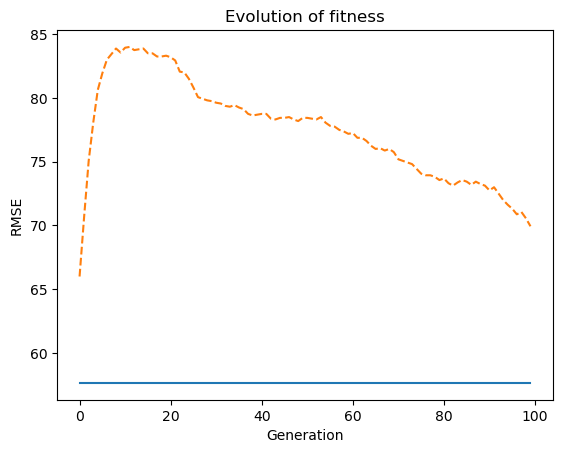

In [4]:
plot_fitess_evolution(history)

## 5. Exploring Mutation operators

in this we want to have an overview of the different mutation operators we will try and why they can be good for our problem

### 5.1. Random per gene reset mutation

this was the first one we used

### 5.2. Gaussian creep mutation

starting with the default gaussian standard deviation of 5

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = gaussian_creep_mutation,
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 65.94, Best: 61.34; Mutation rate: 0.010; 0.77s/iteration
Iteration 10 - Fitness: Avg: 58.62, Best: 54.94; Mutation rate: 0.010; 0.73s/iteration
Iteration 20 - Fitness: Avg: 53.31, Best: 52.75; Mutation rate: 0.010; 0.73s/iteration
Iteration 30 - Fitness: Avg: 51.38, Best: 50.78; Mutation rate: 0.010; 0.73s/iteration
Iteration 40 - Fitness: Avg: 50.25, Best: 49.88; Mutation rate: 0.010; 0.74s/iteration
Iteration 50 - Fitness: Avg: 49.50, Best: 49.09; Mutation rate: 0.010; 0.74s/iteration
Iteration 60 - Fitness: Avg: 48.75, Best: 48.25; Mutation rate: 0.010; 0.74s/iteration
Iteration 70 - Fitness: Avg: 47.81, Best: 47.31; Mutation rate: 0.010; 0.77s/iteration
Iteration 80 - Fitness: Avg: 46.91, Best: 46.59; Mutation rate: 0.010; 0.75s/iteration
Iteration 90 - Fitness: Avg: 46.38, Best: 46.03; Mutation rate: 0.010; 0.74s/iteration
Iteration 100 - Fitness: Avg: 45.66, Best: 45.22; Mutation rate: 0.010; 0.75s/iteration


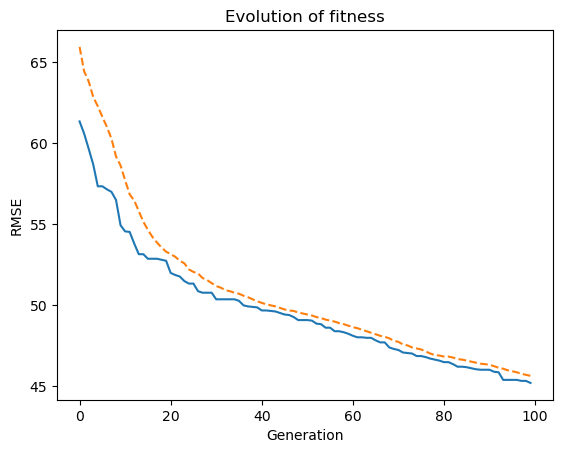

In [5]:
plot_fitess_evolution(history)

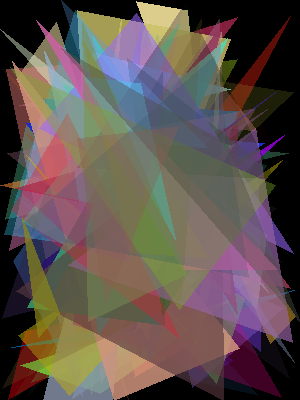

In [6]:
best_solution.render()

testing a std deviation of 1

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = lambda i, m: gaussian_creep_mutation(i, m, gaussian_std_dev=1),
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 65.94, Best: 61.31; Mutation rate: 0.010; 0.83s/iteration
Iteration 10 - Fitness: Avg: 58.31, Best: 55.53; Mutation rate: 0.010; 0.86s/iteration
Iteration 20 - Fitness: Avg: 53.59, Best: 52.28; Mutation rate: 0.010; 0.88s/iteration
Iteration 30 - Fitness: Avg: 51.38, Best: 50.69; Mutation rate: 0.010; 0.74s/iteration
Iteration 40 - Fitness: Avg: 50.22, Best: 49.97; Mutation rate: 0.010; 0.86s/iteration
Iteration 50 - Fitness: Avg: 49.81, Best: 49.62; Mutation rate: 0.010; 0.98s/iteration
Iteration 60 - Fitness: Avg: 49.56, Best: 49.47; Mutation rate: 0.010; 0.77s/iteration
Iteration 70 - Fitness: Avg: 49.44, Best: 49.38; Mutation rate: 0.010; 0.80s/iteration
Iteration 80 - Fitness: Avg: 49.28, Best: 49.22; Mutation rate: 0.010; 0.79s/iteration
Iteration 90 - Fitness: Avg: 49.19, Best: 49.09; Mutation rate: 0.010; 0.76s/iteration
Iteration 100 - Fitness: Avg: 49.00, Best: 48.94; Mutation rate: 0.010; 0.78s/iteration


population diversity is very low at the end of 100 epochs

now testing a std dev of 20

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = lambda i, m: gaussian_creep_mutation(i, m, gaussian_std_dev=20),
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 66.00, Best: 61.41; Mutation rate: 0.010; 0.78s/iteration
Iteration 10 - Fitness: Avg: 59.00, Best: 56.00; Mutation rate: 0.010; 0.79s/iteration
Iteration 20 - Fitness: Avg: 53.47, Best: 51.12; Mutation rate: 0.010; 0.86s/iteration
Iteration 30 - Fitness: Avg: 50.47, Best: 49.09; Mutation rate: 0.010; 0.80s/iteration
Iteration 40 - Fitness: Avg: 48.75, Best: 46.94; Mutation rate: 0.010; 0.88s/iteration
Iteration 50 - Fitness: Avg: 45.41, Best: 44.59; Mutation rate: 0.010; 0.82s/iteration
Iteration 60 - Fitness: Avg: 44.12, Best: 43.44; Mutation rate: 0.010; 0.82s/iteration
Iteration 70 - Fitness: Avg: 43.34, Best: 42.72; Mutation rate: 0.010; 0.81s/iteration
Iteration 80 - Fitness: Avg: 42.66, Best: 42.12; Mutation rate: 0.010; 1.13s/iteration
Iteration 90 - Fitness: Avg: 41.84, Best: 41.06; Mutation rate: 0.010; 0.90s/iteration
Iteration 100 - Fitness: Avg: 41.09, Best: 40.31; Mutation rate: 0.010; 0.98s/iteration


we got a much better score and the population seems to be more diverse at the end

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = lambda i, m: gaussian_creep_mutation(i, m, gaussian_std_dev=20),
    mutation_rate = 0.10
)

Iteration 1 - Fitness: Avg: 66.25, Best: 59.25; Mutation rate: 0.100; 0.88s/iteration
Iteration 10 - Fitness: Avg: 58.31, Best: 54.34; Mutation rate: 0.100; 0.81s/iteration
Iteration 20 - Fitness: Avg: 53.72, Best: 51.72; Mutation rate: 0.100; 0.80s/iteration
Iteration 30 - Fitness: Avg: 52.78, Best: 50.09; Mutation rate: 0.100; 0.85s/iteration
Iteration 40 - Fitness: Avg: 51.00, Best: 49.09; Mutation rate: 0.100; 0.83s/iteration
Iteration 50 - Fitness: Avg: 49.00, Best: 45.81; Mutation rate: 0.100; 0.86s/iteration
Iteration 60 - Fitness: Avg: 48.12, Best: 45.75; Mutation rate: 0.100; 0.80s/iteration
Iteration 70 - Fitness: Avg: 48.09, Best: 45.47; Mutation rate: 0.100; 0.86s/iteration
Iteration 80 - Fitness: Avg: 47.81, Best: 45.25; Mutation rate: 0.100; 0.84s/iteration
Iteration 90 - Fitness: Avg: 48.28, Best: 45.25; Mutation rate: 0.100; 0.86s/iteration
Iteration 100 - Fitness: Avg: 48.03, Best: 45.09; Mutation rate: 0.100; 0.83s/iteration


In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = lambda i, m: gaussian_creep_mutation(i, m, gaussian_std_dev=20),
    mutation_rate = 0.05
)

Iteration 1 - Fitness: Avg: 66.12, Best: 60.59; Mutation rate: 0.050; 0.95s/iteration
Iteration 10 - Fitness: Avg: 56.94, Best: 53.38; Mutation rate: 0.050; 0.91s/iteration
Iteration 20 - Fitness: Avg: 53.19, Best: 50.41; Mutation rate: 0.050; 0.83s/iteration
Iteration 30 - Fitness: Avg: 48.66, Best: 46.88; Mutation rate: 0.050; 0.84s/iteration
Iteration 40 - Fitness: Avg: 47.38, Best: 46.03; Mutation rate: 0.050; 0.81s/iteration
Iteration 50 - Fitness: Avg: 45.91, Best: 44.53; Mutation rate: 0.050; 0.90s/iteration
Iteration 60 - Fitness: Avg: 45.41, Best: 44.22; Mutation rate: 0.050; 0.88s/iteration
Iteration 70 - Fitness: Avg: 45.16, Best: 43.50; Mutation rate: 0.050; 0.92s/iteration
Iteration 80 - Fitness: Avg: 44.25, Best: 43.00; Mutation rate: 0.050; 0.94s/iteration
Iteration 90 - Fitness: Avg: 43.34, Best: 42.25; Mutation rate: 0.050; 1.33s/iteration
Iteration 100 - Fitness: Avg: 42.75, Best: 41.50; Mutation rate: 0.050; 0.91s/iteration


now testing std dev of 50

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = lambda i, m: gaussian_creep_mutation(i, m, gaussian_std_dev=50),
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 66.00, Best: 61.53; Mutation rate: 0.010; 0.93s/iteration
Iteration 10 - Fitness: Avg: 59.06, Best: 56.56; Mutation rate: 0.010; 0.79s/iteration
Iteration 20 - Fitness: Avg: 54.62, Best: 51.88; Mutation rate: 0.010; 0.82s/iteration
Iteration 30 - Fitness: Avg: 51.44, Best: 49.72; Mutation rate: 0.010; 0.79s/iteration
Iteration 40 - Fitness: Avg: 49.25, Best: 47.09; Mutation rate: 0.010; 0.80s/iteration
Iteration 50 - Fitness: Avg: 47.66, Best: 46.34; Mutation rate: 0.010; 0.81s/iteration
Iteration 60 - Fitness: Avg: 46.56, Best: 44.78; Mutation rate: 0.010; 0.77s/iteration
Iteration 70 - Fitness: Avg: 45.34, Best: 44.41; Mutation rate: 0.010; 0.83s/iteration
Iteration 80 - Fitness: Avg: 44.88, Best: 43.09; Mutation rate: 0.010; 0.90s/iteration
Iteration 90 - Fitness: Avg: 43.78, Best: 42.50; Mutation rate: 0.010; 0.78s/iteration
Iteration 100 - Fitness: Avg: 43.44, Best: 41.06; Mutation rate: 0.010; 0.79s/iteration


population seems to be more diverse and convergence was slower, but we still got a good result

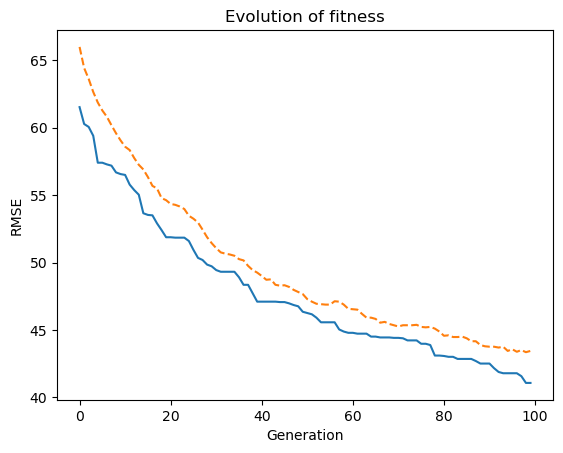

In [6]:
plot_fitess_evolution(history)

### 5.3. Whole triangle mutation

change a whole triangle

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = whole_triangle_mutation,
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 66.25, Best: 61.44; Mutation rate: 0.010; 0.79s/iteration
Iteration 10 - Fitness: Avg: 57.31, Best: 54.22; Mutation rate: 0.010; 0.80s/iteration
Iteration 20 - Fitness: Avg: 52.75, Best: 51.25; Mutation rate: 0.010; 0.77s/iteration
Iteration 30 - Fitness: Avg: 50.69, Best: 48.31; Mutation rate: 0.010; 0.81s/iteration
Iteration 40 - Fitness: Avg: 49.28, Best: 47.78; Mutation rate: 0.010; 0.79s/iteration
Iteration 50 - Fitness: Avg: 48.00, Best: 46.88; Mutation rate: 0.010; 0.77s/iteration
Iteration 60 - Fitness: Avg: 47.19, Best: 46.28; Mutation rate: 0.010; 0.75s/iteration
Iteration 70 - Fitness: Avg: 46.28, Best: 45.19; Mutation rate: 0.010; 0.75s/iteration
Iteration 80 - Fitness: Avg: 45.78, Best: 44.91; Mutation rate: 0.010; 0.77s/iteration
Iteration 90 - Fitness: Avg: 45.75, Best: 44.72; Mutation rate: 0.010; 0.82s/iteration
Iteration 100 - Fitness: Avg: 45.53, Best: 44.62; Mutation rate: 0.010; 0.80s/iteration


In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = whole_triangle_mutation,
    mutation_rate = 0.10
)

Iteration 1 - Fitness: Avg: 66.44, Best: 59.50; Mutation rate: 0.100; 0.81s/iteration
Iteration 10 - Fitness: Avg: 60.69, Best: 55.91; Mutation rate: 0.100; 0.83s/iteration
Iteration 20 - Fitness: Avg: 58.75, Best: 53.19; Mutation rate: 0.100; 0.79s/iteration
Iteration 30 - Fitness: Avg: 57.81, Best: 52.09; Mutation rate: 0.100; 0.76s/iteration
Iteration 40 - Fitness: Avg: 59.44, Best: 51.56; Mutation rate: 0.100; 0.75s/iteration
Iteration 50 - Fitness: Avg: 58.34, Best: 51.56; Mutation rate: 0.100; 0.81s/iteration
Iteration 60 - Fitness: Avg: 57.34, Best: 51.06; Mutation rate: 0.100; 0.74s/iteration
Iteration 70 - Fitness: Avg: 56.53, Best: 50.84; Mutation rate: 0.100; 0.75s/iteration
Iteration 80 - Fitness: Avg: 58.38, Best: 50.84; Mutation rate: 0.100; 0.80s/iteration
Iteration 90 - Fitness: Avg: 59.56, Best: 50.47; Mutation rate: 0.100; 0.80s/iteration
Iteration 100 - Fitness: Avg: 58.62, Best: 50.47; Mutation rate: 0.100; 0.77s/iteration


### 5.4. Layer order mutation

change/swap the layer that a triangle is in

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = layer_order_mutation,
    mutation_rate = 0.01
)

Iteration 1 - Fitness: Avg: 66.19, Best: 62.44; Mutation rate: 0.010; 0.75s/iteration
Iteration 10 - Fitness: Avg: 58.25, Best: 54.25; Mutation rate: 0.010; 0.79s/iteration
Iteration 20 - Fitness: Avg: 53.12, Best: 52.03; Mutation rate: 0.010; 0.73s/iteration
Iteration 30 - Fitness: Avg: 51.28, Best: 50.88; Mutation rate: 0.010; 0.75s/iteration
Iteration 40 - Fitness: Avg: 50.81, Best: 50.56; Mutation rate: 0.010; 0.72s/iteration
Iteration 50 - Fitness: Avg: 50.56, Best: 50.53; Mutation rate: 0.010; 0.76s/iteration
Iteration 60 - Fitness: Avg: 50.53, Best: 50.53; Mutation rate: 0.010; 0.73s/iteration
Iteration 70 - Fitness: Avg: 50.53, Best: 50.53; Mutation rate: 0.010; 0.74s/iteration
Iteration 80 - Fitness: Avg: 50.38, Best: 50.38; Mutation rate: 0.010; 0.75s/iteration
Iteration 90 - Fitness: Avg: 50.31, Best: 50.00; Mutation rate: 0.010; 0.83s/iteration
Iteration 100 - Fitness: Avg: 50.00, Best: 49.97; Mutation rate: 0.010; 0.74s/iteration


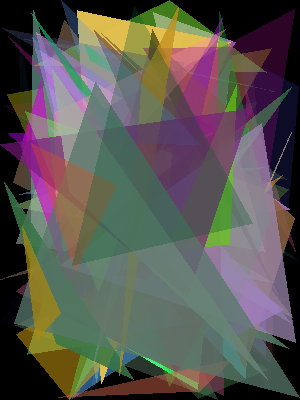

In [4]:
best_solution.render()

## 6. Adptive mutation rate strategies

### 5.1. Mutation rate decay (check if this is the correct naming)

just set a weight decay value so that the value will decrease slowly, as lower mutation rates at the end usually help with results

In [ ]:
np.random.seed(33)
best_solution, history = mutation_weight_decay_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = random_per_gene_reset_mutation,
    mutation_rate = 0.01,
    mutation_rate_decay=1e-3
)

Iteration 1 - Fitness: Avg: 66.10, Best: 60.84; Mutation rate: 0.010; 0.40s/iteration
Iteration 10 - Fitness: Avg: 58.16, Best: 52.88; Mutation rate: 0.010; 0.34s/iteration
Iteration 20 - Fitness: Avg: 53.74, Best: 50.84; Mutation rate: 0.010; 0.30s/iteration
Iteration 30 - Fitness: Avg: 52.06, Best: 49.39; Mutation rate: 0.010; 0.40s/iteration
Iteration 40 - Fitness: Avg: 49.90, Best: 46.97; Mutation rate: 0.010; 0.33s/iteration
Iteration 50 - Fitness: Avg: 49.97, Best: 46.55; Mutation rate: 0.010; 0.31s/iteration
Iteration 60 - Fitness: Avg: 48.83, Best: 45.37; Mutation rate: 0.009; 0.30s/iteration
Iteration 70 - Fitness: Avg: 48.91, Best: 45.37; Mutation rate: 0.009; 0.33s/iteration
Iteration 80 - Fitness: Avg: 47.75, Best: 45.37; Mutation rate: 0.009; 0.30s/iteration
Iteration 90 - Fitness: Avg: 47.02, Best: 44.57; Mutation rate: 0.009; 0.31s/iteration
Iteration 100 - Fitness: Avg: 46.86, Best: 43.68; Mutation rate: 0.009; 0.32s/iteration


In [ ]:
np.random.seed(33)
best_solution, history = mutation_weight_decay_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = random_per_gene_reset_mutation,
    mutation_rate = 0.01,
    mutation_rate_decay=1e-2
)

Iteration 1 - Fitness: Avg: 66.12, Best: 60.84; Mutation rate: 0.010; 1.08s/iteration
Iteration 10 - Fitness: Avg: 58.19, Best: 53.97; Mutation rate: 0.009; 1.10s/iteration
Iteration 20 - Fitness: Avg: 53.81, Best: 50.53; Mutation rate: 0.008; 0.87s/iteration
Iteration 30 - Fitness: Avg: 51.88, Best: 48.94; Mutation rate: 0.007; 0.90s/iteration
Iteration 40 - Fitness: Avg: 50.25, Best: 47.34; Mutation rate: 0.007; 0.99s/iteration
Iteration 50 - Fitness: Avg: 48.78, Best: 46.19; Mutation rate: 0.006; 0.82s/iteration
Iteration 60 - Fitness: Avg: 48.41, Best: 46.19; Mutation rate: 0.006; 0.90s/iteration
Iteration 70 - Fitness: Avg: 46.50, Best: 44.88; Mutation rate: 0.005; 1.08s/iteration
Iteration 80 - Fitness: Avg: 45.16, Best: 43.12; Mutation rate: 0.005; 1.00s/iteration
Iteration 90 - Fitness: Avg: 44.75, Best: 43.12; Mutation rate: 0.004; 0.92s/iteration
Iteration 100 - Fitness: Avg: 44.41, Best: 42.91; Mutation rate: 0.004; 1.08s/iteration


### 5.2. Self-adaptive mutation rate

try self-adaptive mutation rate, so that the mutation rate is tied to each individual so that it is also evolved, the idea is that the best mutation rates will survive naturally

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True, use_self_adaptive_mutation_rate=True),
    population_size = 50,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = random_per_gene_reset_mutation,
    mutation_rate = 0
)

Iteration 1 - Fitness: Avg: 68.68, Best: 60.25; Mutation rate: 0.000; 0.45s/iteration
Iteration 10 - Fitness: Avg: 65.72, Best: 58.24; Mutation rate: 0.000; 0.39s/iteration
Iteration 20 - Fitness: Avg: 63.41, Best: 55.50; Mutation rate: 0.000; 0.35s/iteration
Iteration 30 - Fitness: Avg: 61.96, Best: 54.78; Mutation rate: 0.000; 0.34s/iteration
Iteration 40 - Fitness: Avg: 61.22, Best: 53.98; Mutation rate: 0.000; 0.33s/iteration
Iteration 50 - Fitness: Avg: 60.53, Best: 53.98; Mutation rate: 0.000; 0.32s/iteration
Iteration 60 - Fitness: Avg: 60.32, Best: 51.51; Mutation rate: 0.000; 0.34s/iteration
Iteration 70 - Fitness: Avg: 59.74, Best: 51.51; Mutation rate: 0.000; 0.34s/iteration
Iteration 80 - Fitness: Avg: 57.99, Best: 51.51; Mutation rate: 0.000; 0.34s/iteration
Iteration 90 - Fitness: Avg: 57.58, Best: 51.51; Mutation rate: 0.000; 0.34s/iteration
Iteration 100 - Fitness: Avg: 57.34, Best: 50.95; Mutation rate: 0.000; 0.33s/iteration


In [6]:
best_solution.representation[0]

array([4.00000000e+00, 1.19000000e+02, 2.33000000e+02, 6.00000000e+01,
       1.76000000e+02, 1.19000000e+02, 2.48000000e+02, 1.95000000e+02,
       1.07000000e+02, 1.56000000e+02, 1.98462923e-02])

In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True, use_self_adaptive_mutation_rate=True),
    population_size = 200,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = random_per_gene_reset_mutation,
    mutation_rate = 0
)

Iteration 1 - Fitness: Avg: 67.58, Best: 60.46; Mutation rate: 0.000; 1.58s/iteration
Iteration 10 - Fitness: Avg: 66.68, Best: 56.96; Mutation rate: 0.000; 1.38s/iteration
Iteration 20 - Fitness: Avg: 63.77, Best: 55.93; Mutation rate: 0.000; 1.40s/iteration
Iteration 30 - Fitness: Avg: 62.27, Best: 53.96; Mutation rate: 0.000; 1.35s/iteration
Iteration 40 - Fitness: Avg: 60.57, Best: 52.67; Mutation rate: 0.000; 1.35s/iteration
Iteration 50 - Fitness: Avg: 58.97, Best: 51.94; Mutation rate: 0.000; 1.41s/iteration
Iteration 60 - Fitness: Avg: 58.21, Best: 51.34; Mutation rate: 0.000; 2.05s/iteration
Iteration 70 - Fitness: Avg: 57.70, Best: 50.21; Mutation rate: 0.000; 1.52s/iteration
Iteration 80 - Fitness: Avg: 55.85, Best: 50.04; Mutation rate: 0.000; 1.45s/iteration
Iteration 90 - Fitness: Avg: 55.57, Best: 49.04; Mutation rate: 0.000; 1.48s/iteration
Iteration 100 - Fitness: Avg: 55.66, Best: 49.04; Mutation rate: 0.000; 1.43s/iteration


In [ ]:
np.random.seed(33)
best_solution, history = base_ga_loop(
    solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True, use_self_adaptive_mutation_rate=True),
    population_size = 500,
    n_generations = 100,
    selection_function = lambda p: tournament_selection(p, tournament_size=2),
    crossover_function = uniform_crossover,
    crossover_rate = 0.9,
    mutation_function = random_per_gene_reset_mutation,
    mutation_rate = 0
)

Iteration 1 - Fitness: Avg: 68.38, Best: 57.24; Mutation rate: 0.000; 3.95s/iteration
Iteration 10 - Fitness: Avg: 65.17, Best: 54.95; Mutation rate: 0.000; 3.52s/iteration
Iteration 20 - Fitness: Avg: 62.63, Best: 53.91; Mutation rate: 0.000; 4.04s/iteration
Iteration 30 - Fitness: Avg: 60.92, Best: 52.44; Mutation rate: 0.000; 3.95s/iteration
Iteration 40 - Fitness: Avg: 59.05, Best: 49.58; Mutation rate: 0.000; 3.52s/iteration
Iteration 50 - Fitness: Avg: 57.51, Best: 48.75; Mutation rate: 0.000; 3.56s/iteration
Iteration 60 - Fitness: Avg: 56.04, Best: 48.75; Mutation rate: 0.000; 4.17s/iteration
Iteration 70 - Fitness: Avg: 54.17, Best: 47.43; Mutation rate: 0.000; 4.81s/iteration
Iteration 80 - Fitness: Avg: 52.85, Best: 47.35; Mutation rate: 0.000; 4.33s/iteration
Iteration 90 - Fitness: Avg: 51.51, Best: 45.41; Mutation rate: 0.000; 3.78s/iteration
Iteration 100 - Fitness: Avg: 50.52, Best: 45.06; Mutation rate: 0.000; 4.42s/iteration


## 7. Combat insufficient population diversity

try fitness sharing or restricted mating

## ~~8. Hyperparameter tuning~~

We can do this, just do a random search or grid search, the teacher said it should be coded by us

The hand-written loop above worked for exploring the idea, but the actual random search is run by the orchestrated version below so that progress and output are controlled in one place.

In [ ]:
# Replaced by the orchestrated `random_search(...)` implementation below.

now check what was the best solution and its parameters

maybe try to make the random search parallelizable

In [ ]:
from multiprocessing import Manager
from queue import Empty
from threading import Event, Thread

from joblib import Parallel, delayed
from tqdm.auto import tqdm


def sample_random_search_params(param_grid, rng):
    return {
        "population_size": int(rng.choice(param_grid["population_size"])),
        "n_iterations": int(param_grid["n_iterations"]),
        "tournament_size": int(rng.choice(param_grid["tournament_size"])),
        "crossover_function": rng.choice(param_grid["crossover_function"]),
        "crossover_rate": float(rng.choice(param_grid["crossover_rate"])),
        "mutation_function": rng.choice(param_grid["mutation_function"]),
        "mutation_rate": float(rng.choice(param_grid["mutation_rate"])),
        "mutation_rate_decay": rng.choice(param_grid["mutation_rate_decay"]),
        "use_self_adaptive_mutation_rate": rng.choice(param_grid["use_self_adaptive_mutation_rate"])
    }


def run_random_search_trial(run_id, params, seed=33, progress_queue=None, verbose=False):
    np.random.seed(seed + run_id)

    def report_generation_complete():
        if progress_queue is not None:
            progress_queue.put(1)

    best_solution, history = mutation_weight_decay_ga_loop(
        solution_class=lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True, use_self_adaptive_mutation_rate=params["use_self_adaptive_mutation_rate"]),
        population_size=params["population_size"],
        n_generations=params["n_iterations"],
        selection_function=lambda p: tournament_selection(p, tournament_size=params["tournament_size"]),
        crossover_function=uniform_crossover,
        crossover_rate=params["crossover_rate"],
        mutation_function=random_per_gene_reset_mutation,
        mutation_rate=params["mutation_rate"],
        mutation_rate_decay=params["mutation_rate_decay"],
        progress_callback=report_generation_complete,
        verbose=verbose,
    )

    return {
        "run_id": run_id,
        "best_fitness": best_solution.fitness,
        "best_solution": best_solution,
        "history": history,
        **params,
    }


def update_generation_progress(progress_queue, progress_bar, stop_event):
    while not stop_event.is_set():
        try:
            progress_step = progress_queue.get(timeout=0.2)
        except Empty:
            continue

        progress_bar.update(progress_step)

    while True:
        try:
            progress_step = progress_queue.get_nowait()
        except Empty:
            break

        progress_bar.update(progress_step)


def random_search(n_trials: int, param_grid, n_jobs: int = -1, seed: int = 33, verbose: bool = False):
    rng = np.random.default_rng(seed)
    sampled_params = [sample_random_search_params(param_grid, rng) for _ in range(n_trials)]
    total_generations = sum(params["n_iterations"] for params in sampled_params)

    if total_generations == 0:
        return []

    with Manager() as manager:
        progress_queue = manager.Queue()
        stop_event = Event()

        with tqdm(total=total_generations, desc="Random search generations", unit="gen") as progress_bar:
            progress_thread = Thread(
                target=update_generation_progress,
                args=(progress_queue, progress_bar, stop_event),
                daemon=True,
            )
            progress_thread.start()

            try:
                jobs = (
                    delayed(run_random_search_trial)(run_id, params, seed=seed, progress_queue=progress_queue, verbose=verbose)
                    for run_id, params in enumerate(sampled_params)
                )
                results = Parallel(n_jobs=n_jobs)(jobs)
            finally:
                stop_event.set()
                progress_thread.join()

            if progress_bar.n < total_generations:
                progress_bar.update(total_generations - progress_bar.n)

    return sorted(results, key=lambda result: result["best_fitness"])


c:\Users\Asus\anaconda3\envs\CIFO2526\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
param_grid = {
    "population_size": [100, 200, 400, 600, 800],
    "n_iterations": 200,
    "tournament_size": [2, 3, 5, 10],
    "crossover_function": [uniform_crossover, one_point_row_crossover, two_point_row_crossover, geometry_color_separated_uniform_crossover, arithmetic_blend_crossover],
    "crossover_rate": [0.9, 0.8, 0.7],
    # add the multiple std dev values for gaussian creep mutation
    "mutation_function": [random_per_gene_reset_mutation, gaussian_creep_mutation, whole_triangle_mutation, layer_order_mutation],
    "mutation_rate": [0.1, 0.05, 0.01, 0.001],
    "mutation_rate_decay": [None, 1e-2, 1e-3, 1e-4],
    "use_self_adaptive_mutation_rate": [True, False]
}

In [6]:
random_search_results = random_search(100, param_grid, n_jobs=12)

Random search generations: 100%|██████████| 20000/20000 [5:22:24<00:00,  1.03gen/s]  


In [7]:
random_search_results[0]

{'run_id': 42,
 'best_fitness': np.float32(26.373476),
 'best_solution': <src.solution.Solution at 0x1b3b4f1bc10>,
 'history': {'avg_fitness': [np.float32(63.291225),
   np.float32(60.47918),
   np.float32(58.445225),
   np.float32(56.824352),
   np.float32(55.383095),
   np.float32(53.88268),
   np.float32(52.477413),
   np.float32(51.445885),
   np.float32(50.40285),
   np.float32(49.62584),
   np.float32(49.026867),
   np.float32(48.35067),
   np.float32(47.562218),
   np.float32(47.060654),
   np.float32(46.402443),
   np.float32(45.784733),
   np.float32(45.478867),
   np.float32(45.053078),
   np.float32(44.630264),
   np.float32(44.350784),
   np.float32(43.855087),
   np.float32(43.58144),
   np.float32(43.12482),
   np.float32(42.784325),
   np.float32(42.346264),
   np.float32(41.998146),
   np.float32(41.645008),
   np.float32(41.298607),
   np.float32(41.002472),
   np.float32(40.74498),
   np.float32(40.357533),
   np.float32(40.021072),
   np.float32(39.729847),
   np.flo

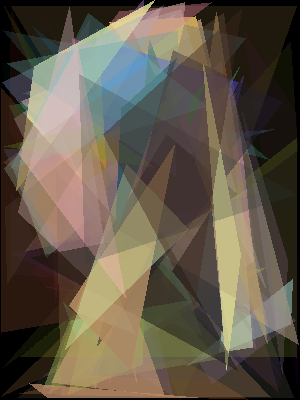

In [8]:
random_search_results[0]["best_solution"].render()

see if there is a way to link to the specific functions in each .py file when writing the final notebook

we need some visualizations like boxplots of all of the different variants, idk

C:\Users\Asus\AppData\Local\Temp\ipykernel_18240\2499351948.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


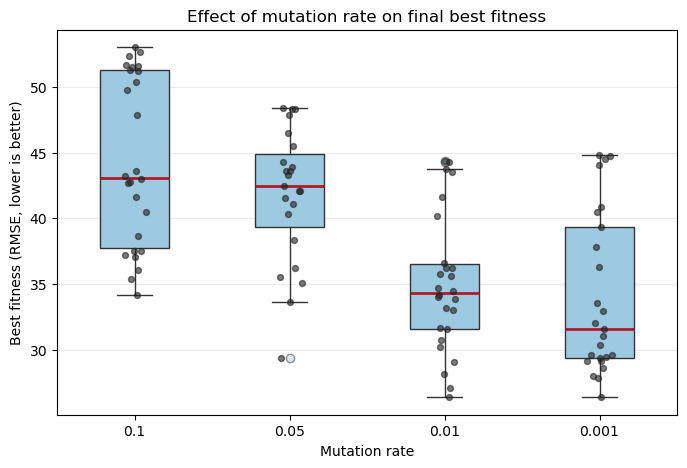

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

search_results_df = pd.DataFrame(random_search_results)

mutation_rate_values = param_grid["mutation_rate"]
fitness_by_mutation_rate = [
    search_results_df.loc[
        search_results_df["mutation_rate"] == mutation_rate,
        "best_fitness",
    ].values
    for mutation_rate in mutation_rate_values
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    fitness_by_mutation_rate,
    labels=[str(rate) for rate in mutation_rate_values],
    patch_artist=True,
    boxprops={"facecolor": "#9ecae1", "edgecolor": "#333333"},
    medianprops={"color": "#b2182b", "linewidth": 2},
    whiskerprops={"color": "#333333"},
    capprops={"color": "#333333"},
    flierprops={"marker": "o", "markerfacecolor": "#9ecae1", "alpha": 0.4},
)

rng = np.random.default_rng(33)
for position, fitness_values in enumerate(fitness_by_mutation_rate, start=1):
    jitter = rng.normal(0, 0.04, size=len(fitness_values))
    ax.scatter(
        position + jitter,
        fitness_values,
        color="#222222",
        alpha=0.6,
        s=18,
        zorder=3,
    )

ax.set_title("Effect of mutation rate on final best fitness")
ax.set_xlabel("Mutation rate")
ax.set_ylabel("Best fitness (RMSE, lower is better)")
ax.grid(axis="y", alpha=0.25)
plt.show()

not all of the runs are comparable, since not all the parameters were the same and it could have different population sizes

we need to do what the teacher talked about in class

## 9. Final solutions

 'population_size': 800,
 'n_iterations': 200,
 'tournament_size': 10,
 'crossover_function': <function src.crossover.one_point_row_crossover(parent1: src.solution.Solution, parent2: src.solution.Solution, crossover_rate: float) -> tuple[src.solution.Solution, src.solution.Solution]>,
 'crossover_rate': 0.9,
 'mutation_function': <function src.mutation.whole_triangle_mutation(individual: src.solution.Solution, mutation_rate: float) -> src.solution.Solution>,
 'mutation_rate': 0.01,
 'mutation_rate_decay': 0.01,
 'use_self_adaptive_mutation_rate': np.False_

In [10]:
best_solution, history = mutation_weight_decay_ga_loop(
        solution_class=lambda: Solution(
            IMAGE_WIDTH,
            IMAGE_HEIGHT,
            N_TRIANGLES,
            TARGET_IMAGE_ALPHA,
            use_transparency=True,
            use_self_adaptive_mutation_rate=False
        ),
        population_size=800,
        n_generations=1000,
        selection_function=lambda p: tournament_selection(p, tournament_size=10),
        crossover_function=one_point_row_crossover,
        crossover_rate=0.9,
        mutation_function=lambda i, m: gaussian_creep_mutation(i, m, gaussian_std_dev=20),
        mutation_rate=0.01,
        mutation_rate_decay=1e-3,
        # progress_callback=report_generation_complete,
        # verbose=verbose,
    )

Iteration 1 - Fitness: Avg: 63.06, Best: 56.54; Mutation rate: 0.010; 6.96s/iteration
Iteration 10 - Fitness: Avg: 49.95, Best: 48.45; Mutation rate: 0.010; 7.16s/iteration
Iteration 20 - Fitness: Avg: 44.29, Best: 43.35; Mutation rate: 0.010; 6.62s/iteration
Iteration 30 - Fitness: Avg: 41.14, Best: 40.12; Mutation rate: 0.010; 5.82s/iteration
Iteration 40 - Fitness: Avg: 38.64, Best: 37.85; Mutation rate: 0.010; 5.35s/iteration
Iteration 50 - Fitness: Avg: 36.64, Best: 36.10; Mutation rate: 0.010; 5.35s/iteration
Iteration 60 - Fitness: Avg: 34.94, Best: 34.38; Mutation rate: 0.009; 5.86s/iteration
Iteration 70 - Fitness: Avg: 33.70, Best: 33.11; Mutation rate: 0.009; 6.18s/iteration
Iteration 80 - Fitness: Avg: 32.40, Best: 31.98; Mutation rate: 0.009; 8.82s/iteration
Iteration 90 - Fitness: Avg: 31.49, Best: 30.92; Mutation rate: 0.009; 6.30s/iteration
Iteration 100 - Fitness: Avg: 30.47, Best: 30.04; Mutation rate: 0.009; 5.63s/iteration
Iteration 110 - Fitness: Avg: 29.59, Best: 

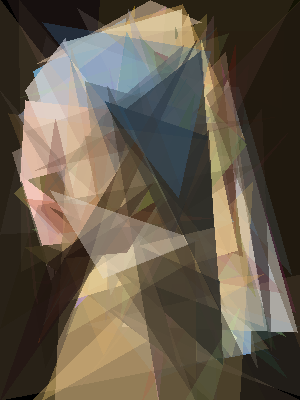

In [11]:
best_solution.render()

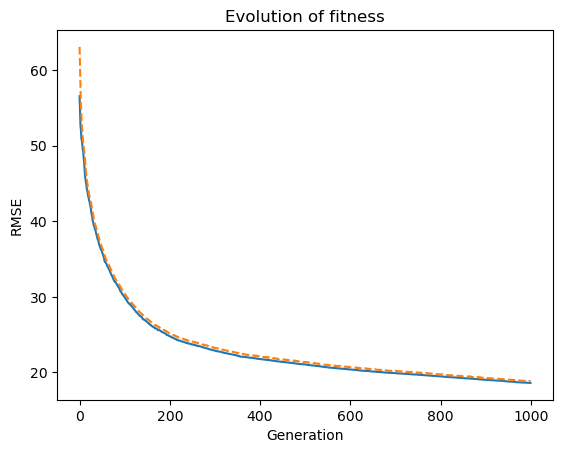

In [12]:
plot_fitess_evolution(history)